# FM-Index Backward Search

Count and locate exact substring matches by narrowing an interval in suffix-array order.

The Burrows–Wheeler last column and prefix occurrence counts permit a backward extension of the current query. This demonstrator builds the suffix array by sorting strings and stores a full rank table, which makes the working storage deliberately easy to inspect.

In [1]:
from pathlib import Path
import sys

here = Path.cwd()
sys.path.insert(0, str(here.parent))
import numpy as np
import matplotlib.pyplot as plt

from genome_methods import fm_index, backward

## Worked example

Run the example from top to bottom. The printed check and figure use the same observations.

BWT ACTTTCGGGAAA$AATTAA
Zero-based matches [0, 7, 12]
Widths [19, 5, 3, 3]


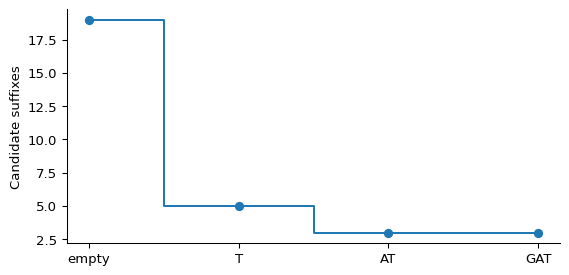

In [2]:
text = "GATTACAGATTAGATACA"
query = "GAT"
index = fm_index(text)
hits, width = backward(query, index)
assert hits == [i for i in range(len(text)) if text.startswith(query, i)]
print("BWT", index[1])
print("Zero-based matches", hits)
print("Widths", width)
plt.figure(figsize=(6.1, 3))
plt.step(range(len(width)), width, where="mid")
plt.scatter(range(len(width)), width)
plt.xticks(range(len(width)), ["empty"] + [query[-i:] for i in range(1, len(query) + 1)])
plt.ylabel("Candidate suffixes")
plt.tight_layout()
plt.show()

## Interpreting the result

Every extension restricts the interval. An interval of width zero proves that the exact query is absent.

## Exercise

Try a query that occurs twice with an overlap. Confirm both returned offsets directly.

## References

[Ferragina and Manzini, opportunistic indexing (2000)](https://doi.org/10.1109/SFCS.2000.892127)